# Evaluation metrics

## 1 - Rollout design

### How the stimulus is driven during a rollout

A `CLsemi` block places its dots **relative to the fish once, at block onset** (~74 px away,
~±90° to the side) and the dot track is predefined from then on — it does not chase the fish.
There are two ways to reproduce that for a simulated fish:

| mode | what it does | `stimulus_tool` |
|---|---|---|
| **physical** | replay the absolute dot positions real fish *N* saw | `PROGRAM = 0…14` |
| **re-anchored** | keep the fish-relative programme, latch a new anchor at each block onset from **the rollout's own pose** | `PROGRAM = None` |

**One programme drives all fifteen fish.** The stored offsets are fish-relative, and anchoring is
a rotation plus a translation — rotation preserves magnitude — so every fish gets the *identical*
centroid distance in a given block while sitting somewhere completely different in the dish.
Measured: within-block spread across the 15 fish is **0.00 px**, in 95/95 blocks (block 0 = 69.0 px
for everyone, block 2 = 85.4, block 3 = 74.2). Onset distance is therefore a property of the
**block**, not of the fish, and all the variation is between blocks (sd 18.8 px, from group size
and dot layout).

A re-anchored rollout replays those same offsets, so it gets **exactly** the per-block value the
real fish had — not merely a draw from the same distribution.

**We use re-anchored.** Not just for realism: the physical programme evaluates the model almost
entirely outside the regime the real data occupies. Pairing each fish's recorded dot track with a
*different* fish's position at block onset — which is what a physical programme does to a rollout
that is not the fish it was built from:

| onset distance (px) | p5 | p25 | **p50** | p75 | p95 | max |
|---|---|---|---|---|---|---|
| real, anchored | 42 | 62 | **73** | 85 | 108 | **121** |
| physical programme | 34 | 80 | **124** | 174 | 251 | 390 |

*(The real row is 95 distinct block values — one per block, identical for all 15 fish — so its
effective n is 95, not 1425. The physical row genuinely varies per fish, over the 95 × 15 × 14
pairings, because it depends on where the other fish happened to be.)*

Real onset distance is hard-bounded at **121 px**; the physical programme starts **41 %** of
blocks beyond 140 px, where no real block ever starts, and its **median** block (124 px) already
sits past the real 99th percentile. Only 41 % land in the 40–120 px band that holds 96 % of real
blocks.

That matters because the moving-dot range response peaks at **60–80 px** (P(turn toward) 0.685)
and falls to 0.598 beyond 150 px. A rollout starting at 124 px begins on the far, declining limb,
so it looks less stimulus-responsive than a real fish **purely from placement** — the model gets
blamed for geometry. Every stimulus-referenced metric (following index, approach curve, range
tuning) is then an extrapolation.

⚠ **The trade.** Re-anchoring makes the stimulus **endogenous**: a model that swims differently
*gets* a different stimulus, so two models can no longer be compared all-else-equal on any
fish-to-shoal quantity. That is exactly what the physical programme is for — holding the dots in
fixed absolute places so differences between rollouts are behaviour rather than placement — so
keep it for the individuality question, and never compare numbers across the two modes.

⚠ **One known mismatch.** The rig biased placement inward (the shoal falls within 90° of the
dish-centre direction on 59 % of bouts); the programme's fish-relative offsets are fixed at ±90°.
So a wall-hugging rollout will put dots outside the dish more often than the rig did — real data
has the centroid outside on 11.4 % of bouts. Worth logging as a rollout diagnostic.

⚠ **The anchor is latched at the first BOUT of the block**, not at the block-onset frame. For a
rollout that is exact under dart-and-hold (the fish is stationary between bouts). For a real fish
it is not — `stim_rollout` measures median ~4 px, p90 ~81 px of anchor error from that rule.

## 2 - Metric A - per bout likelihood loss

The way the loss is defined guides the model training, since this is what model optimizes.

Each bout emits three channels — turn $\Delta\theta$, step length $\ell$, interval $\tau$ — so
the per-bout density is a joint over all three, conditioned on the feature vector $x_t$:

$$p(\Delta\theta_t,\; \ell_t,\; \tau_t \mid x_t)$$

The chain rule factorises this **exactly, in any of the $3! = 6$ orderings**. So the ordering is
not a modelling assumption about the data — it is a choice about which conditionals each head has
to represent, and it only matters because the heads have finite capacity.



**Joint model** (`fit_MLP_joint`) — one feature vector, one shared body, chained heads:

$$\mathcal{L} \;=\; -\sum_t \Big[ \log p(\Delta\theta_t \mid x_t) \;+\; \log p(\ell_t \mid x_t, |\Delta\theta_t|) \;+\; \log p(\tau_t \mid x_t, |\Delta\theta_t|, \log \ell_t) \Big]$$

Each channel is conditioned on everything already sampled **within the same bout**.

**Kin model** (`fit_MLP_mix.MLPMixKinDensity`) — two trunks, and the turn is independent:

$$\mathcal{L} \;=\; -\sum_t \Big[ \log p(\Delta\theta_t \mid x^{\text{ang}}_t) \;+\; \log p(\ell_t \mid x^{\text{kin}}_t) \;+\; \log p(\tau_t \mid x^{\text{kin}}_t, \log \ell_t) \Big]$$

Here $x^{\text{kin}}$ is the kinematic-history block **only**, so distance and interval never see
the stimulus, the wall or the turn history.

**The ordering the EDA argues for** — $\tau$ first, because $|\Delta\theta|$ scales with the time
spanned ($\rho = 0.17$) and not with the distance ($\rho = -0.01$), so a head that emits them
independently will draw 170° turns onto 0.5 s gaps:

$$\mathcal{L} \;=\; -\sum_t \Big[ \log p(\tau_t \mid x_t) \;+\; \log p(\Delta\theta_t \mid x_t, \log\tau_t) \;+\; \log p(\ell_t \mid x_t, \log\tau_t, |\Delta\theta_t|) \Big]$$

This is **not implemented**. Since the chain rule is exact either way, it is a capacity argument,
and the honest test is to fit the orderings and compare **held-out joint** likelihood.

### Conventions that are easy to get wrong

- **Conditioners use $|\Delta\theta|$, not signed $\Delta\theta$.** Left and right should not change
  step size or timing, and feeding the sign would break a symmetry the turn mixture otherwise
  enforces. They are scaled exactly as the matching history blocks are (`/dth_scale`, centred by
  `kin_scales`), so the heads see inputs on the scale they were trained at.
- **Emissions:** $\Delta\theta$ is a 5-component mixture; $\ell$ is log-normal (`n_dist`
  components); $\tau$ is a log-normal mixture (`n_dt`) conditioned on $\log \ell$.
- **$\tau$ should be a TRUNCATED log-normal mixture.** Training on `active` bouts means the
  data stops dead at 10 s, but an untruncated mixture puts mass past that edge — mass the
  masking rule guarantees is empty. Renormalising on the support the model is actually fitted
  to costs one term in the NLL:
  $$\log p_{\text{trunc}}(\tau) = \log p(\tau) - \log F(10\,\text{s}),\qquad
  F(10) = \sum_k w_k\,\Phi\!\left(\frac{\log 10 - \mu_k}{\sigma_k}\right)$$
  differentiable via `torch.special.ndtr`, with sampling drawn from the truncated support
  (inverse-CDF, or reject-and-redraw). Without it a small irreducible `dt_w1` penalty is
  baked in — a smooth mixture cannot reproduce a hard cut — and it would be misread as a
  model defect rather than a specification mismatch. **Not yet implemented.**
- **Targets are NaN-masked**, so a bout missing distance or interval still contributes its turn
  term.

### ⚠ Two different likelihoods

`MLPMixKinDensity` **fits** all three channels but inherits a `score` that evaluates **only the
turn mixture** — so about two thirds of the fitted emission is optimised against a number that is
never reported. `fit_MLP_joint.score` returns `logdens` (turn, same key as before) plus
`logdens_dist` and `logdens_dt`.

So "the likelihood" is ambiguous unless the channel is named. When comparing models, check which
one a stored number is: a turn-only figure and a three-channel figure are not comparable, and the
turn-only convention is a **reporting** convention, not something the fit enforces.

## 3 - Metric B - rollout similarity

Metric A scores the model where the real fish actually went (teacher-forced, one bout ahead).
Metric B lets the model **run free** and asks whether the trajectories it produces look like real
ones. A model can win on A and lose badly on B — matching every one-step conditional says nothing
about what happens when its own errors feed back in.

`generative_metrics.panel_for_fish` runs **R rollouts per held-out fish** and reports the mean;
`summarize_panel` then bootstraps across fish. **Every panel metric is a gap: 0 = identical to
real, larger = worse.** The omnibus scores in group F are the exception and are read differently.

⚠ **The real reference must be masked to `active` too.** The model is trained on active bouts,
so it emits no gaps; `build_records` keeps `good = isfinite(dtheta_deg)` with **no** active
filter, so out of the box gen and real describe different populations. Left unmasked, `dt_w1`
is dominated by a tail the model was told not to produce, `dist_w1` and `abs_dtheta_w1` are
contaminated by gap rows where those columns describe the pause, and the C2ST features
`dt_std` / `dt_q90` / `dt_acf1` become near-perfect discriminators that mask every real defect
behind them.

### A · Per-bout marginals — does each channel have the right shape?

| metric | compares |
|---|---|
| `abs_dtheta_w1` | Wasserstein-1 between gen and real \|Δθ\| |
| `dist_w1` | W1 on step length |
| `dt_w1` | W1 on inter-bout interval |
| `symbol_js` | Jensen–Shannon on the F / L / R symbol frequencies |

The easiest group to pass, and the one that proves least — an i.i.d. head can match all four.

### B · Short-range sequence structure — bout to bout

| metric | compares |
|---|---|
| `trans_js` | JS on the 3×3 symbol transition matrix |
| `acf_l2` | L2 over the Δθ autocorrelation at lags 1, 2, 3, 4, 5, 8, 12 |
| `runlen_w1` | W1 on the length of F / L / R runs |
| `bigram_H_gap` | conditional entropy of symbol bigrams |

This is where an i.i.d. head first fails: it reproduces the marginal and still emits isolated
kinks where real fish make arcs.

### C · Stimulus response — the load-bearing group

| metric | compares |
|---|---|
| `tuning_mse` | the P(turn toward) vs bearing tuning curve |
| `following_gap_h` · `following_gap_static_h` | following index, moving / static — **honest bearing**: gen's own travel-framed bearing against the travel-framed real index |
| `approach_gap` | the approach curve (distance to dots vs time in block) |
| `dot_dist_w1` | distribution of fish-to-shoal distance |
| `dot_dist_bias` | mean fish-to-shoal distance |
| `time_near_dot_gap` · `time_far_gap` | time spent close to / far from the shoal |

The `_h` pair matters because of the frame issue: `stim_angle` is body-axis referenced while a
rollout only has its travel heading. The `_h` metrics compare travel-framed gen against
travel-framed real, so the comparison is frame-matched rather than carrying a 40.6° mismatch.

⚠ **The plain `following_gap` / `following_gap_static` are dropped** for closed-loop rollouts.
They score the generated turns against `rec.stim_angle` — the **real fish's** recorded bearing
sequence — which a re-anchored rollout never saw: it reacted to its own bearing, from its own
pose and its own latched anchor. Turn *t* is then graded against a stimulus it did not
experience, so once the trajectories diverge even a perfect model scores badly, and the metric
measures drift rather than following. They stay correct for **teacher-forced / non-loop**
models, which genuinely do condition on `rec.stim_angle`, and the code routes there
automatically (`gb = rec.stim_angle if stim_angle_gen is None`).

⚠ Because of that same fallback, **check the rollouts actually populate `stim_angle_gen`** — if
they do not, `_h` silently collapses onto the non-`_h` quantity and you are reading the wrong
metric under the right name.

⚠ **`dot_dist_bias_late` and `dot_dist_w1_late` are dropped.** They existed because under a
physical programme `dot_dist_bias` was ~2/3 a block-onset placement artefact — the rollout
started a block at a median 124 px against the real 73 — so the early part of the block had to
be cut. Under re-anchoring that contamination is **exactly zero**: anchoring is a rotation plus
a translation, rotation preserves magnitude, so the rollout's onset distance is the identical
per-block value the real fish had. `dot_dist_bias` over the whole block is now a clean
behavioural measure and the split has nothing left to remove. The code still computes them
until the rollout switch lands; ignore them, and never compare a stored `_late` value across
the two modes.

### D · Space and containment

| metric | compares |
|---|---|
| `wall_frac_gap` | fraction of bouts in the wall shell |
| `rad_*` (via C2ST) | radial occupancy — mean, median, q90, `rad_frac_wall` |

Kept separate from group C on purpose: a radial defect is a **containment** failure, not a
stimulus one, and lumping it into the dot-distance group is exactly the misattribution to avoid.

### E · Long timescale — where the model is known to fail

| metric | compares |
|---|---|
| `win_acf1` | across-window autocorrelation of window features (**windows built within runs**) |
| `var_ratio` | gen vs real variance of window statistics (>1 = over-dispersed) |
| `bf_sd` | SD across fish of the per-fish window mean — how different the fish are |
| `wf_sd` | mean within-fish SD across windows — how variable one fish is |
| `bf_w1` | Wasserstein-1 between the real and gen sets of per-fish means — shape, not just spread |

⚠ This group carries the known 6σ failure: real across-window acf ≈ **+0.33**, model ≈ **0**,
because every individuality mechanism tried so far is *static*. `between_fish_share` is a **level
to match**, not a gap to minimise.

##### Dropped: `quiesc_frac`, `rate_acf_*`, `win_chan_corr`

**`quiesc_frac`** is time-weighted by definition — the fraction of *elapsed* time in gaps longer
than a threshold. Training on active bouts only means the model does not attempt quiescence, so
unmasked it fails trivially (gen ≈ 0 against real ≈ 30 %) and masked it is trivially satisfied
(both ≈ 0). It carries no information about the model either way.

**`rate_acf_3min_gap`** is not estimable. It builds its own clock as `t = cumsum(dt)`, so on
active data that clock is *compressed* — a "minute" is a minute of active time — and a naive
cumsum splices across gaps, re-creating exactly the discontinuity `run_id` exists to prevent. It
therefore has to be computed **within runs**, and runs are short:

```
979 runs, 1784 min of active time out of 2596 min recorded
run duration (active s): median 37   p75 109   p90 286

runs >=  60 s: 373  holding 89.8 % of active bouts   (1-min lag: workable)
runs >= 180 s: 162  holding 70.1 %                   (3-min lag: 1 run for fish 6, 4 for fish 10)
```

**Measured, and it settles the question — `rate_acf` goes entirely:**

| real reference | 1 min | 2 min | 3 min |
|---|---|---|---|
| unmasked, wall clock (archived) | 0.509 | 0.323 | 0.219 |
| active, spliced `cumsum` (wrong) | 0.350 | 0.167 | 0.130 |
| **active, within runs ≥ 4 min** | **0.049** | −0.208 | −0.320 |

Computed properly inside continuous active stretches, bout-rate autocorrelation is
**≈ 0 at 1 min**, and the negative 2/3-min values are the small-sample signature of a
4-minute run holding only ~4 one-minute bins (the 3-min lag rests on a single pair). So it
is not that the metric becomes unfair — the phenomenon is **not there** once the gaps are
removed. A model scoring 0 would match perfectly and mean nothing. Drop all of it.

**`win_chan_corr`** goes for the same reason. It correlates per-window channel means and
needs windows that are inside one run *and* adjacent in time; more importantly it reads the
coupling that the mask removes — the shared slow state moves dt, distance and turning
together largely *through stopping*. Still a useful diagnostic on unmasked real data, so
the function stays; it is `timing_report`'s `cpl_dt_dist_gap` / `cpl_dt_turn_gap` that
should be ignored.

⚠ **What this costs.** The slow-arousal band lives substantially *in* the quiescence — active
bouts per wall-clock bin have acf1 **0.266** under no stimulus against **−0.086** under moving.
Masking the gaps does not fix the slow-state defect; it makes part of it **unmeasurable**. Record
the wall-clock arousal band as outside the model's declared scope rather than as a failure it is
being scored on.

### F · Omnibus discriminators — read differently

| metric | reading |
|---|---|
| `c2st_auc` | classifier two-sample test on 20 turn/symbol window features. **0.5 = indistinguishable**, 1.0 = trivially separable |
| `c2st_traj_auc` | the same on up to **39** features (+ distance 5, dt 5, dot-distance 5, radial 4) |
| `mmd2_permutation` | kernel MMD² with a permutation p-value |
| `c2st_importances` | *which* features make the trajectory detectable, grouped as turn / distance / dt / dot-dist / radial |
| `c2st_negative_control` | real-vs-real AUC — the floor a perfect model would reach |
| `dispersion_report` | per-feature gen/real spread, to separate "wrong mean" from "wrong variance" |

⚠ **Read `c2st_importances` before trusting any AUC.** Defects mask each other roughly 40× — a
single large defect can dominate the classifier and hide everything else, so a null on some
mechanism may be masked rather than refuted. And always compare against
`c2st_negative_control`: `c2st_traj` has an SD around 0.017, so differences smaller than that are
noise.

### Between-fish differences — `bf_sd`, `wf_sd`, `bf_w1`

`between_fish_share` is **dropped**. It is a ratio, `B / (B + W)`, so numerator and denominator
can be wrong together and cancel: a model with half the between-fish spread *and* half the
within-fish spread scores a perfect share. Demonstrated — real 0.953 / gen 0.957 on synthetic
data where both parts are off by 2×.

Three absolute replacements, in the feature's own units, computed by
`generative_metrics.between_fish_metrics`:

| metric | what it is | what it catches |
|---|---|---|
| `bf_sd` | SD **across fish** of the per-fish window mean | how different the fish are from each other |
| `wf_sd` | mean over fish of that fish's SD **across its own windows** | how variable one fish is — the denominator the ratio hid |
| `bf_w1` | Wasserstein-1 between the real and generated sets of per-fish means | **shape**, not just spread — whether the model produces an outlier fish at all |

`bf_w1` is the one that adds something the other two cannot: real fish include genuine outliers
(fish 14 turns >150° on 8.2 % of bouts against 0.37–2.31 % for the rest), and a model can match
`bf_sd` with fifteen mediocre fish and no outlier.

The plot below is the picture those three numbers summarise, on **real active bouts**: each dot
is one fish's mean, each bar that fish's own within-fish spread. **`bf_sd` is how scattered the
dots are; `wf_sd` is how long the bars are.** A model can fail either independently.

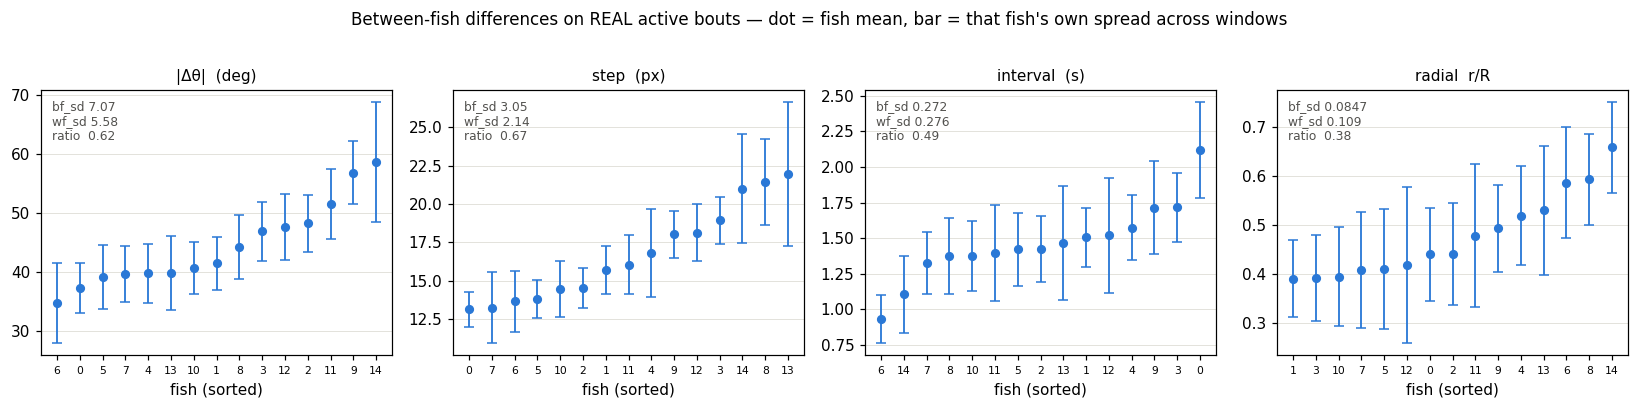

channel              bf_sd     wf_sd    ratio  min fish  max fish
|Δθ|  (deg)          7.066     5.584     0.62         6        14
step  (px)           3.053     2.139     0.67         0        13
interval  (s)       0.2718     0.276     0.49         6         0
radial  r/R        0.08471     0.109     0.38         1        14

The ratio column is what between_fish_share reported. Two channels sit near the same
ratio with very different absolute spreads -- which is the reason it was dropped.


In [ ]:
import matplotlib.pyplot as plt

W = 60
BLUE, INK2, GRID = "#2a78d6", "#52514e", "#e1e0d9"
d = pd.read_csv(ROOT / "clean_data" / "bouts_clean.csv")
a = d[d.active].copy()
a["absdth"] = a.dtheta_deg.abs()

CH = [("absdth", "|Δθ|  (deg)"), ("distance_px", "step  (px)"),
      ("dt_s", "interval  (s)"), ("r_norm", "radial  r/R")]
FISH = sorted(a.fish_id.unique())

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
for j, (col, lab) in enumerate(CH):
    mu, sd = [], []
    for f in FISH:
        g = a[a.fish_id == f]
        # non-overlapping windows INSIDE a run -- same rule the metrics use
        vals = []
        for _, run in g.groupby("run_id"):
            v = run[col].to_numpy(float)
            for s0 in range(0, len(v) - W + 1, W):
                vals.append(np.nanmean(v[s0:s0 + W]))
        vals = np.array(vals)
        mu.append(np.nan if len(vals) < 2 else vals.mean())
        sd.append(np.nan if len(vals) < 2 else vals.std(ddof=1))
    mu, sd = np.array(mu), np.array(sd)
    o = np.argsort(mu)
    x = np.arange(len(FISH))
    ax[j].errorbar(x, mu[o], yerr=sd[o], fmt="o", ms=5, color=BLUE, capsize=3, lw=1.2)
    ax[j].set_xticks(x)
    ax[j].set_xticklabels([FISH[i] for i in o], fontsize=7)
    ax[j].set_xlabel("fish (sorted)")
    ax[j].set_title(lab, fontsize=10)
    bf, wf = np.nanstd(mu, ddof=1), np.nanmean(sd)
    ax[j].text(.03, .96, f"bf_sd {bf:.3g}\nwf_sd {wf:.3g}\nratio  {bf**2/(bf**2+wf**2):.2f}",
               transform=ax[j].transAxes, va="top", fontsize=8, color=INK2)
    ax[j].grid(axis="y", color=GRID, lw=.6, zorder=0)
    ax[j].set_axisbelow(True)
fig.suptitle("Between-fish differences on REAL active bouts — dot = fish mean, bar = that fish's "
             "own spread across windows", y=1.02, fontsize=11)
fig.tight_layout(); plt.show()

print(f"{'channel':<16}{'bf_sd':>10}{'wf_sd':>10}{'ratio':>9}{'min fish':>10}{'max fish':>10}")
for col, lab in CH:
    mu = []
    for f in FISH:
        g = a[a.fish_id == f]
        vals = [np.nanmean(run[col].to_numpy(float)[s0:s0 + W])
                for _, run in g.groupby("run_id")
                for s0 in range(0, len(run) - W + 1, W)]
        mu.append(np.mean(vals) if len(vals) > 1 else np.nan)
    sd = []
    for f in FISH:
        g = a[a.fish_id == f]
        vals = [np.nanmean(run[col].to_numpy(float)[s0:s0 + W])
                for _, run in g.groupby("run_id")
                for s0 in range(0, len(run) - W + 1, W)]
        sd.append(np.std(vals, ddof=1) if len(vals) > 1 else np.nan)
    mu, sd = np.array(mu), np.array(sd)
    bf, wf = np.nanstd(mu, ddof=1), np.nanmean(sd)
    print(f"{lab:<16}{bf:>10.4g}{wf:>10.4g}{bf**2/(bf**2+wf**2):>9.2f}"
          f"{FISH[int(np.nanargmin(mu))]:>10}{FISH[int(np.nanargmax(mu))]:>10}")
print("\nThe ratio column is what between_fish_share reported. Two channels sit near the same")
print("ratio with very different absolute spreads -- which is the reason it was dropped.")